# 20. От фотографий до собственной статической сцены

[План курса](../../README_ru.md)

На столе лежат девять фотографий скульптуры. Положения камер уже получены. Теперь можно закрыть один снимок, учиться по оставшимся восьми и в конце открыть закрытый. Если скульптура узнаётся и с той стороны, модель узнала что-то о пространстве.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'


## 1. Как выглядит начало

В опыте с цветными пятнами центры и размеры заданы заранее. Серый цвет одинаков у всех. Один шаг меняет RGB по трём обучающим видам одновременно. В наборе фотографий центры приходят из разреженного облака. Справа от модели доступен выбор камеры. Смещение камеры в сторону даёт дополнительный вид без фотографии-эталона. Здесь особенно заметно, что рендерер хранит одну общую сцену. Браузер уточняет цвета при закреплённой геометрии. В расчёте Python ниже откроются ещё центры, три ширины, поворот и непрозрачность.


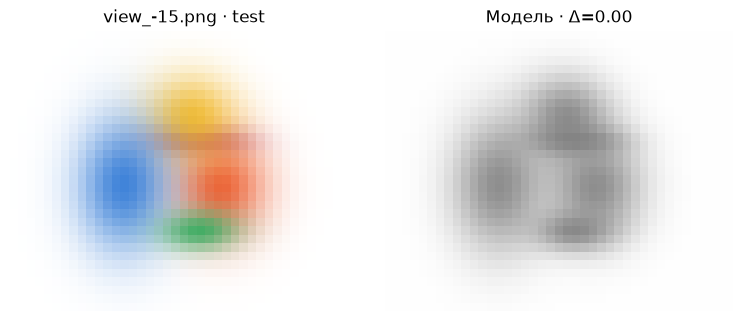

In [2]:
frames, initial = synthetic_capture()
def small_view(steps, offset):
    model, _ = fit_colors(initial, frames, int(steps))
    return view_figure(frames, model, 1, offset, lang)
display(small_view(0,0)); plt.close()
controls(small_view, steps=(0,24,1,0), offset=(-.2,.2,.005,0))


## 2. От пикселя к первому шагу

Возьмём один красный канал. Цвет первого пятна $c=0.5$. В нашем пикселе ему достаётся вес $w=T\alpha=0.6$. Белый фон занимает оставшиеся 0.4. Рендер даёт $P=0.6\cdot0.5+0.4\cdot1=0.7$. На фотографии $Y=0.58$. Остаток $P-Y=0.12$, его квадрат $0.0144$. Увеличение красного на 0.01 увеличит $P$ на $0.6\cdot0.01=0.006$, то есть цвет уже слишком яркий.

Для квадрата ошибки производная по цвету равна $2(P-Y)w$. Множитель 2 приходит от квадрата, остаток сохраняет знак, $w$ говорит, какая доля луча вообще видит это пятно. Получается $2\cdot0.12\cdot0.6=0.144$. При размере шага 0.5 новое значение $0.5-0.5\cdot0.144=0.428$. Тогда $P=0.6568$, и квадрат остатка около $0.00590$. В полной картинке к сумме добавляются все пиксели всех обучающих видов. Пустые области дают малую информацию о конкретном пятне.

Почему первые шаги получаются такими быстрыми? При закреплённой форме веса не меняются. Для пикселя $j$ сохраняем $w_{ji}$ — вес видимого пятна $i$ — и $b_j$, долю белого фона. Тогда $P_j=b_j+\sum_i w_{ji}c_i$. Большой знак означает «сложить вклады всех пятен». Например, при весах 0.6 и 0.1, фоне 0.3 и цветах 0.5 и 0.2 выходит $0.3+0.6\cdot0.5+0.1\cdot0.2=0.62$. В коде столбец массива весов отвечает одному пятну, строка одному пикселю. Можно заранее сложить произведения весов по пикселям. Так очередной шаг RGB обходится без нового проектирования. Результат каждого канала удерживается в пределах от 0 до 1.


In [3]:
w,c,b,target = .6,.5,.4,.58
pred = b+w*c
updated = c-.5*2*(pred-target)*w
print("color:", c, "→", updated)
print("loss:", (pred-target)**2, "→", (b+w*updated-target)**2)
assert (b+w*updated-target)**2 < (pred-target)**2


color: 0.5 → 0.428
loss: 0.0144 → 0.005898240000000014


## 3. Данные, которые можно унести с собой

Теперь подставим настоящие снимки. Это **PhysicalAI-NuRec-PPISP, struktur28_auto, NVIDIA Corporation, CC BY 4.0**. В курсе девять адаптированных кадров по 160 × 120, уже без дисторсии. Восемь обучающих фотографий дали 117 триангулированных точек при известных положениях камер. Координаты и цвет этих точек не вычислялись по пикселям девятого кадра. Для быстрого опыта возьмём 24 точки и уменьшим кадр до 40 × 30. Ставим серые гауссианы с одинаковой начальной непрозрачностью. Более полное облако может дать больше деталей, но увеличит цену каждого шага. [Происхождение и преобразования фотографий](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example)

Папка **capture** ниже содержит PNG, камеры, начальные параметры и метки train/test. Внутри текущей рабочей папки ноутбука появится каталог **static-scene-result** с моделью и отдельным JSON-файлом для веб-версии. Фактический путь возвращает `out.resolve()`. Для своей съёмки та же функция `load_colmap(text_model, images_dir, test_names=[...])` принимает папки урока 19 и имена отложенных снимков. Имена соответствуют строкам images.txt, включая расширение и вложенные каталоги. Желательно, чтобы удержанный ракурс был отделён от соседних серийных дублей.


У собственной реконструкции, рассчитанной по всем фотографиям, разбиение в загрузчике исключает тестовый цвет из градиентов. Но исходные точки и позы могли уже использовать его двумерные признаки. Для строгой проверки облако строится только по обучающим наблюдениям, а для тестовой камеры отдельно фиксируется поза. Именно так разделены пиксели и треки у приложенного примера; исходная калибровка известна для всей съёмки.

In [4]:
photos, seed = photo_capture(max_side=40, max_points=24)
out = Path.cwd() / "static-scene-result"
write_capture(out/"capture", photos, seed)
photos, seed = read_capture(out/"capture")
export_browser_capture(photos, seed, out/"capture-browser.json")
warm, color_loss = fit_colors(seed, photos, steps=12)
print("views:", len(photos), "splats:", len(seed["splats"]))
print("train RGB MSE:", round(color_loss[0],6), "→", round(color_loss[-1],6))


views: 9 splats: 24
train RGB MSE: 0.336137 → 0.25423


## 4. Почему серым точкам мало одного цвета

Если пятно оказалось левее каменного края, смена оттенка не передвинет его. Теперь граф вычислений длиннее. Трёхмерный центр преобразуется в камеру, деление на глубину даёт экранное положение, форма и поворот задают ковариацию следа. В каждом пикселе появляются вес и прозрачность, дальше RGB, разность с фотографией и квадрат. PyTorch проходит по той же цепочке обратно. Все камеры видят **одни и те же** параметры. Каждое обновление усредняет ошибку внутри кадра и затем по восьми кадрам.

Три ширины должны быть положительными. Храним числа $\ell$ без ограничения, а в рендер передаём $s=\exp(\ell)$. При $\ell=0$ ширина равна 1, при $\ell=-0.6931$ — примерно 0.5 единицы сцены. Для непрозрачности и цвета храним $a$, а отображаем $1/(1+\exp(-a))$. При $a=0$ выходит $1/(1+1)=0.5$. Отрицательные значения приближают выход к нулю, положительные — к единице. Четыре числа поворота делим на их общую длину, как в уроке 12. Такой способ оставляет форму допустимой при каждом шаге.

В первом опыте для одного цвета был обычный шаг градиента. Для разных параметров в следующем опыте Adam накапливает среднее направление и масштаб квадратов недавних градиентов. Если один параметр постоянно даёт большие числа, нормировка уменьшает его относительный шаг. Значение 0.017 в коде задаёт общий масштаб обновления. В этой версии 30 шагов и 24 пятна остаются фиксированными. Цвет от направления взгляда, изменение плотности и сложная потеря нужны в более полном опыте. Здесь интересен сам переход от разреженного облака к изменяемому изображению.


saved: static-gaussians.json  RGB MSE: 0.25423 → 0.056428


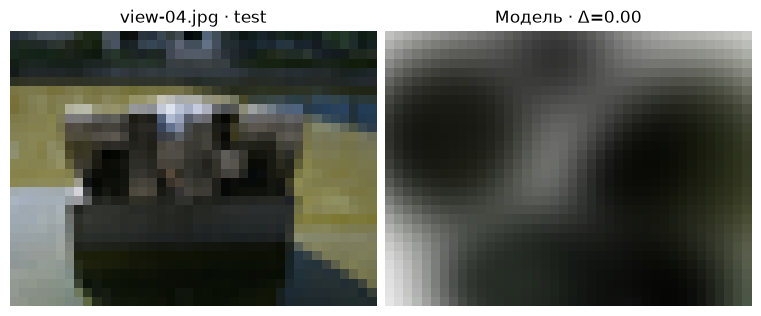

In [5]:
import torch
from reconstruction_fit import refine_scene
torch.set_num_threads(1)
trained, fit_loss = refine_scene(warm, photos, steps=30, rate=.017)
model_path = out/"static-gaussians.json"
model_path.write_text(json.dumps(trained, indent=2, allow_nan=False), encoding="utf8")
opened = json.loads(model_path.read_text(encoding="utf8"))
test_index = next(i for i,f in enumerate(photos) if f["split"]=="test")
f = photos[test_index]
h,w = f["rgb"].shape[:2]
assert np.allclose(render_scene(opened,f["camera"],w,h),render_scene(trained,f["camera"],w,h))
print("saved:", model_path.name, " RGB MSE:", round(fit_loss[0],6), "→", round(fit_loss[-1],6))
display(view_figure(photos, opened, test_index, lang=lang)); plt.close()


## 5. Что открывает просмотрщик

В **static-gaussians.json** для каждого пятна лежат три координаты центра, три ширины, четыре числа поворота, три канала цвета и одна непрозрачность. Камеры лежат рядом, в наборе, потому что снимок зависит и от сцены, и от точки наблюдения. В веб-опыте урока сначала открывается `capture-browser.json`, затем `static-gaussians.json` в том же поле. Браузер рисует загруженную сцену камерами этого набора. Отложенный снимок можно сопоставить с рендером, а затем сдвинуть камеру. При сдвиге число ошибки исчезает: для нового пикселя пока нет измерения. Небольшому браузерному опыту подходят кадры до 128 × 128 и до 128 пятен с ограничением на общий объём расчёта. Оба файла остаются на устройстве.

На сайте набор фотографий открывается с отложенного вида. В списке наборов есть также **«Готовая скульптура · 117 пятен»**. Этот вариант обучался 1200 шагов на тех же восьми видах, по 256 обучающих пикселей за шаг. Он открывается сразу для осмотра и экспорта. При оценке полного кадра 80 × 60 MSE на view-04 равна примерно 0.00982, или 20.08 дБ. В браузере эта готовая сцена сравнивается с тем же снимком 80 × 60. [Обучение модели из 117 пятен](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)

Есть ли здесь детали камня? У модели мало пятен, широта направлений ограничена, цвет одинаков при любом ракурсе. На картинке угадываются крупные массы и цвет фона, тонкие края могут теряться. Оценка качества отдельно в следующем уроке.


In [6]:
controls(lambda view, offset: view_figure(photos, opened, int(view), offset, lang),
         view=list(range(len(photos))), offset=(-.2,.2,.01,0))
print("model file:", model_path.name, " capture file: capture-browser.json")


model file: static-gaussians.json  capture file: capture-browser.json


## 6. Те же фотографии в реализации авторов

Полноразмерный опыт работает в отдельном окружении официального проекта с CUDA, его расширением растеризации и совместимой NVIDIA GPU. Команды ниже выполняются в установленной реализации авторов. Здесь используются **те же результаты коррекции дисторсии**, что и в уроке 19. В папке `scene/images` лежат файлы из `capture/undistorted/images`. В `scene/sparse/0` лежит содержимое `capture/undistorted/sparse`, включая бинарные cameras.bin, images.bin и points3D.bin. Имена изображений остаются такими же, как в модели. Текстовый экспорт нужен нашему учебному загрузчику, бинарный — реализации авторов.

```sh
python train.py -s scene -m models/sculpture --eval
python render.py -m models/sculpture
python metrics.py -m models/sculpture
SIBR_gaussianViewer_app -m models/sculpture
```

SIBR здесь — установленный просмотрщик авторов, исполняемый файл из каталога bin. В Windows его имя оканчивается на .exe. Путь после `-m` ведёт к **папке модели** с настройками и сохранённым облаком в point_cloud/iteration_…/point_cloud.ply. У этого PLY другая схема и параметризация, чем у учебного JSON. Программа train.py меняет плотность и учит параметры внешнего вида в сферических гармониках. С `--eval` стандартный загрузчик COLMAP у авторов откладывает каждый восьмой снимок после сортировки по имени (при обычном разбиении). Наш опыт явно откладывает view-04. Сравнивать значения двух запусков полезно только при одинаковом наборе тестовых видов, разрешении и фоне. [Официальный проект и зависимости](https://github.com/graphdeco-inria/gaussian-splatting) · [Код разбиения кадров](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/dataset_readers.py)

## Опыт

После сохранения сцены камера переместилась. Какие числа в файле гауссиан при этом меняются?

<details><summary>Разбор</summary>

Ни одно. Новые экранные координаты, размеры следов и порядок по глубине пересчитывает рендерер. Обучение меняет саму сцену, навигация по готовой сцене меняет лишь наблюдателя.

</details>
